# Figures and Tables for ISMIR 2026

Reproduces the tables and figures of the paper from the evaluation results in [`results/`](results/):

| Folder | Content |
| --- | --- |
| `results/note_level/` | Track-wise evaluation of the MIDI output of every model in Table 5 (`evaluate_note_level_baselines.py`), incl. the pre-trained baselines MT3, NoteEM and BP |
| `results/frame_level/` | Track-wise evaluation incl. the frame output (`MPE_*`), Table 4 |
| `results/consistency/` | Cross-version consistency on RUBATO, pairwise per version pair, Table 5 and Figure 5 |
| `results/maestro/` | MAESTRO experiments, Section 5.3 |
| `results/decoding_sweep.csv` | Note-level F-measure for a sweep over the onset threshold, Figure 4 |

Results are named after the experiment configs in `configs/experiment/` with the seed as suffix.
The LaTeX rows use macros of the paper source (`\paramL`, `\aboveBaseline`, ...).

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS_DIR = Path("results")
FIG_DIR = Path("outputs/ismir2026_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = pd.read_csv("configs/data/ismir2026_splits.csv")[["id", "dataset"]]

DATASET_LABELS = {
    'rubato': 'RUBATO',
    'rwc2': 'RWC-C',
    'guitarSet': 'GuitarSet',
    'phoenixAnechoic': 'PHENICX',
    'csd': 'CSD',
    'bach10': 'Bach10',
    'trios': 'TRIOS',
    'maestro': 'MAESTRO',
}

# pre-trained models from literature, evaluated with the same pipeline
BASELINES = ['BP', 'MT3', 'NoteEM']
# (dataset, model) pairs where the test set was part of the model's training data
SEEN = {('guitarSet', 'MT3'), ('guitarSet', 'BP')}
# CP-L was trained with three seeds; "CP" in Table 5 is their mean
CP_SEEDS = ['CP-L_42', 'CP-L_43', 'CP-L_44']

PARAM_MACROS = {
    'CP-XS': r'\paramXS', 'CP-S': r'\paramS', 'CP-M': r'\paramM', 'CP-XL': r'\paramXL',
    'BP': r'\paramBP', 'BP+': r'\paramBP', 'MT3': r'\paramMT3', 'NoteEM': r'\paramOnF',
}
LATEX_NAMES = {
    'CP': 'CP (-L)',
    'CP-frame_loss': r'CP-$\mathcal{L}_{\text{f}}$',
    'CP-onset_loss': r'CP-$\mathcal{L}_{\text{o}}$',
}


def strip_seed(run):
    # 'CP-L_42' -> 'CP-L', 'MT3' -> 'MT3'
    name, _, seed = run.rpartition('_')
    return name if seed.isdigit() else run


def latex_name(run):
    name = strip_seed(run)
    return LATEX_NAMES.get(name, name)


def param_macro(run):
    return PARAM_MACROS.get(strip_seed(run), r'\paramL')


def load_track_results(path):
    # track-wise results with the dataset of each track
    df = pd.read_csv(path)
    df['id'] = df['id'].astype(str)
    return df.merge(SPLITS, on='id', how='left')

## Table 1: Model Size Variants
Number of parameters of the model configs.

In [23]:
from hydra import compose, initialize_config_dir
from omegaconf import OmegaConf
from src.model.assembler import Assembler

rows = []
with initialize_config_dir(version_base=None, config_dir=str(Path("configs").resolve())):
    for experiment in ["CP-XS", "CP-S", "CP-M", "CP-L", "CP-XL", "BP+", "DRCNN-M+"]:
        cfg = compose("config", overrides=[f"experiment={experiment}"])
        OmegaConf.resolve(cfg)
        model = Assembler(cfg.model)
        n_params = sum(p.numel() for p in model.parameters())
        rows.append({"model": experiment, "params": n_params})
pd.DataFrame(rows)

,model,params
0,CP-XS,11742
1,CP-S,48182
2,CP-M,289222
3,CP-L,1056202
4,CP-XL,3119802
5,BP+,13310
6,DRCNN-M+,1512783


## Figure 1: Teaser
Piano roll of a score excerpt. Requires the RUBATO dataset, set `RUBATO_DIR` accordingly.

In [24]:
from matplotlib.colors import LinearSegmentedColormap
from src.data.utils import midi_file_to_note_events, note_events_to_binary_mpe_array

RUBATO_DIR = Path("/path/to/rubato")
score_file = RUBATO_DIR / "01_RawData/score_midi/Brahms_Op115-01.mid"

if score_file.exists():
    note_events = midi_file_to_note_events(score_file)
    step = 0.08
    times = np.arange(0, 200 + step, step)
    piano_roll = note_events_to_binary_mpe_array(note_events, times, min_note=24, n_pitch_bins=72, add_onsets=True)

    BLACK_KEYS = {1, 3, 6, 8, 10}
    fig, ax = plt.subplots(figsize=(14, 9))
    for i in range(72):
        if (24 + i) % 12 in BLACK_KEYS:
            ax.axhspan(i, i + 1, color="#edeff0", zorder=0)
    cmap = LinearSegmentedColormap.from_list('custom', ['white', "#707F9CFF", "#040404"])
    cmap.set_under(alpha=0)
    sns.heatmap(piano_roll, cmap=cmap, cbar=False, ax=ax, vmin=0.01)
    ax.set_xlim(28.8 / step, 34.6 / step)
    ax.set_ylim(41, 25)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.tight_layout()
    plt.savefig(FIG_DIR / "piano_roll_example.png", dpi=600)
    plt.show()
else:
    print(f"{score_file} not found, skipping the teaser figure")

/path/to/rubato/01_RawData/score_midi/Brahms_Op115-01.mid not found, skipping the teaser figure


## Table 4: Frame Output (MPE)
Frame-level F-measure and average precision of the raw frame activations.

In [25]:
datasets = ['rubato', 'rwc2', 'phoenixAnechoic', 'trios']
for run in ['DRCNN-M+_42', 'CP-L_42', 'CP-frame_loss_42']:
    df = load_track_results(RESULTS_DIR / "frame_level" / f"{run}.csv.gz")
    means = (df.groupby('dataset')[['MPE_f_meas', 'MPE_average_precision']].mean() * 100).round(1)
    cells = [f"{means.loc[d, m]:.1f}" for d in datasets for m in ['MPE_f_meas', 'MPE_average_precision']]
    name = 'CP' if run == 'CP-L_42' else latex_name(run)
    print(f"{name} & " + " & ".join(cells) + r" \\")

DRCNN-M+ & 70.7 & 78.0 & 69.2 & 78.5 & 81.5 & 90.2 & 79.4 & 89.9 \\
CP & 75.7 & 82.0 & 67.5 & 79.7 & 82.3 & 90.1 & 80.2 & 92.2 \\
CP-$\mathcal{L}_{\text{f}}$ & 75.6 & 81.8 & 67.1 & 79.1 & 81.9 & 90.3 & 80.0 & 92.1 \\


## Figure 4: Decoding Threshold Sensitivity
Note-level F-measure (100 ms, over all test sets) for different onset thresholds.

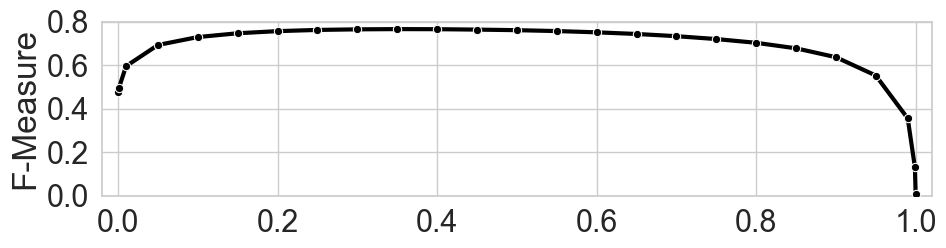

In [26]:
sns.set_theme(style="whitegrid", font_scale=2)
df = pd.read_csv(RESULTS_DIR / "decoding_sweep.csv")
metric = 'AMT_100_F-measure_no_offset'

plt.figure(figsize=(10, 3))
sns.lineplot(data=df, x='onset_threshold', y=metric, marker='o', zorder=100, linewidth=3, color="#000000")
plt.xlabel(None)
plt.ylabel('F-Measure')
plt.yticks([0, 0.2, 0.4, 0.6, 0.8])
plt.xlim(-0.02, 1.02)
plt.ylim(0, 0.8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'onset_threshold_lineplot.pdf', dpi=600)
plt.show()

## Table 5: Note Output
Dataset-wise means of the note-level F-measure (100 ms onset tolerance, no offset), the frame-level F-measure of the decoded notes and the cross-version consistency (CVC) on RUBATO.

In [27]:
metrics = ["AMT_100_F-measure_no_offset", "AMT_200_F-measure_no_offset", "AMT_FRAME_f_meas"]

rows = []
for path in sorted((RESULTS_DIR / "note_level").glob("*.csv*")):
    df = load_track_results(path)
    run = path.name.removesuffix(".gz").removesuffix(".csv")
    row = {"experiment": run}
    for metric in metrics:
        for dataset, val in df.groupby("dataset")[metric].mean().items():
            row[f"{dataset}_{metric}"] = val
        dataset_cols = [k for k in row if k.endswith(metric) and k != f"avg_{metric}"]
        row[f"avg_{metric}"] = np.mean([row[k] for k in dataset_cols])
    consistency_file = RESULTS_DIR / "consistency" / f"{run}.csv.gz"
    if consistency_file.exists():
        row["rubato_cvc"] = pd.read_csv(consistency_file)["lpc_value"].mean()
    rows.append(row)
performance_df = pd.DataFrame(rows)

# mean and standard deviation over the seeds of CP-L
seed_rows = performance_df[performance_df["experiment"].isin(CP_SEEDS)]
numeric_cols = seed_rows.select_dtypes(include="number").columns
mean_row = seed_rows[numeric_cols].mean().to_frame().T
mean_row.insert(0, "experiment", "CP")
std_row = seed_rows[numeric_cols].std().to_frame().T
std_row.insert(0, "experiment", "CP_std")
performance_df = pd.concat([performance_df, mean_row, std_row], ignore_index=True)

numeric_cols = performance_df.select_dtypes(include="number").columns
performance_df[numeric_cols] = (performance_df[numeric_cols] * 100).round(1)
performance_df = performance_df.set_index("experiment")
performance_df

,bach10_AMT_100_F-measure_no_offset,csd_AMT_100_F-measure_no_offset,guitarSet_AMT_100_F-measure_no_offset,phoenixAnechoic_AMT_100_F-measure_no_offset,rubato_AMT_100_F-measure_no_offset,rwc2_AMT_100_F-measure_no_offset,trios_AMT_100_F-measure_no_offset,avg_AMT_100_F-measure_no_offset,bach10_AMT_200_F-measure_no_offset,csd_AMT_200_F-measure_no_offset,...,avg_AMT_200_F-measure_no_offset,bach10_AMT_FRAME_f_meas,csd_AMT_FRAME_f_meas,guitarSet_AMT_FRAME_f_meas,phoenixAnechoic_AMT_FRAME_f_meas,rubato_AMT_FRAME_f_meas,rwc2_AMT_FRAME_f_meas,trios_AMT_FRAME_f_meas,avg_AMT_FRAME_f_meas,rubato_cvc
experiment,,,,,,,,,,,,,,,,,,,,,
BP+_42,76.2,40.3,82.8,67.6,56.8,71.2,76.6,67.4,76.7,49.1,...,70.1,87.2,80.9,82.0,76.9,64.7,63.2,77.7,76.1,62.4
BP,75.8,29.9,80.2,55.0,43.3,61.2,70.7,59.4,78.5,43.1,...,64.3,86.8,72.5,82.4,71.6,54.3,56.1,68.6,70.3,49.5
CP-L_42,94.1,65.2,88.6,72.7,64.3,81.0,88.4,79.2,94.6,83.6,...,83.3,92.0,86.5,81.5,81.7,74.0,66.5,80.0,80.3,70.8
CP-L_43,93.7,63.9,87.9,72.9,64.7,81.8,89.2,79.1,94.3,81.9,...,83.3,92.0,86.9,81.6,81.2,74.2,66.7,80.4,80.4,70.3
CP-L_44,93.8,65.8,88.9,72.8,64.6,81.4,88.9,79.4,94.3,83.4,...,83.5,92.5,86.7,82.7,80.6,74.4,67.1,80.7,80.7,70.8
CP-Less_42,92.0,60.9,88.1,70.8,61.0,77.9,85.5,76.6,92.5,78.0,...,80.6,91.5,85.6,81.6,80.5,70.5,66.2,76.7,79.0,65.5
CP-M_42,93.1,58.9,87.9,71.9,63.6,80.2,87.7,77.6,93.8,79.2,...,82.0,91.0,85.6,82.7,80.8,72.6,66.2,78.1,79.6,69.0
CP-MusicNet_42,85.4,38.8,86.4,72.7,60.4,75.4,84.3,71.9,90.1,46.8,...,75.1,87.6,80.0,79.1,77.8,71.5,63.7,76.5,76.6,65.9
CP-S_42,88.7,49.8,86.3,69.6,61.4,75.6,82.0,73.3,89.4,66.1,...,77.3,90.6,83.7,83.0,78.2,70.3,65.0,75.3,78.0,65.6


In [28]:
cols = ['avg_AMT_100_F-measure_no_offset', 'avg_AMT_FRAME_f_meas',
        'rubato_AMT_100_F-measure_no_offset', 'rubato_AMT_FRAME_f_meas', 'rubato_cvc',
        'rwc2_AMT_100_F-measure_no_offset', 'rwc2_AMT_FRAME_f_meas',
        'guitarSet_AMT_100_F-measure_no_offset', 'guitarSet_AMT_FRAME_f_meas',
        'phoenixAnechoic_AMT_100_F-measure_no_offset', 'phoenixAnechoic_AMT_FRAME_f_meas',
        'csd_AMT_100_F-measure_no_offset', 'csd_AMT_200_F-measure_no_offset', 'csd_AMT_FRAME_f_meas',
        'bach10_AMT_100_F-measure_no_offset', 'bach10_AMT_FRAME_f_meas',
        'trios_AMT_100_F-measure_no_offset', 'trios_AMT_FRAME_f_meas']


def is_seen(run, col):
    return (col.split('_')[0], strip_seed(run)) in SEEN


# best baseline per column, ignoring test sets that were part of the training data
baseline_runs = BASELINES + ['BP+_42']
best_baseline = {col: max(performance_df.loc[r, col] for r in baseline_runs if not is_seen(r, col)) for col in cols}

# upper part: baselines, best value underlined
for run in baseline_runs:
    cells = []
    for col in cols:
        cell = f"{performance_df.loc[run, col]:.1f}"
        if is_seen(run, col):
            cell = f"\\seen{{{cell}}}"
        elif performance_df.loc[run, col] == best_baseline[col]:
            cell = f"\\underline{{{cell}}}"
        cells.append(cell)
    print(f"{latex_name(run)} & {param_macro(run)} & " + " & ".join(cells) + r" \\")
print(r"\midrule")

# middle and lower part: CP variants and ablations, colored by comparison to the best baseline
runs = ['CP', 'CP_std', 'CP-XL_42', 'CP-M_42', 'CP-S_42', 'CP-XS_42', 'CP-MusicNet_42', 'CP-Less_42',
        'L1-BCE_42', 'L2-BCE+tolerance_42', 'L3-BCE+weight_42', 'CP-onset_loss_42', 'R1-Overfit_42']
for run in runs:
    row = performance_df.loc[run, cols]
    if run == 'CP_std':
        cells = [f"$\\pm${v:.1f}".replace("0.", ".") for v in row]
        print(r"$\pm$ std. dev & \paramL & " + " & ".join(cells) + r" \\")
        continue
    if run == 'R1-Overfit_42':  # all test sets are seen in training
        cells = [f"\\seen{{{v:.1f}}}" for v in row]
    else:
        cells = [f"\\aboveBaseline{{{v:.1f}}}" if v > best_baseline[col] else f"\\belowBaseline{{{v:.1f}}}"
                 for col, v in row.items()]
    print(f"{latex_name(run)} & {param_macro(run)} & " + " & ".join(cells) + r" \\")
    if run in ['CP-XS_42', 'CP-Less_42', 'L3-BCE+weight_42', 'CP-onset_loss_42']:
        print(r"\midrule")

BP & \paramBP & 59.4 & 70.3 & 43.3 & 54.3 & 49.5 & 61.2 & 56.1 & \seen{80.2} & \seen{82.4} & 55.0 & 71.6 & 29.9 & 43.1 & 72.5 & 75.8 & 86.8 & 70.7 & 68.6 \\
MT3 & \paramMT3 & 65.4 & 67.4 & 54.2 & 58.9 & 44.8 & \underline{73.9} & 60.6 & \seen{95.9} & \seen{94.0} & 60.9 & 59.2 & 27.2 & 37.8 & 59.9 & 72.6 & 70.6 & 73.1 & 68.6 \\
NoteEM & \paramOnF & \underline{69.9} & 72.9 & 50.4 & 60.7 & 57.2 & 66.1 & \underline{63.6} & \underline{85.8} & \underline{82.0} & \underline{69.6} & 71.0 & \underline{46.6} & \underline{63.9} & 66.7 & \underline{83.8} & 85.4 & \underline{87.4} & \underline{81.2} \\
BP+ & \paramBP & 67.4 & \underline{76.1} & \underline{56.8} & \underline{64.7} & \underline{62.4} & 71.2 & 63.2 & 82.8 & \underline{82.0} & 67.6 & \underline{76.9} & 40.3 & 49.1 & \underline{80.9} & 76.2 & \underline{87.2} & 76.6 & 77.7 \\
\midrule
CP (-L) & \paramL & \aboveBaseline{79.3} & \aboveBaseline{80.5} & \aboveBaseline{64.5} & \aboveBaseline{74.2} & \aboveBaseline{70.7} & \aboveBaseline{81.4}

## Section 5.3: MAESTRO
Note-level F-measure with 50 ms onset tolerance on the MAESTRO v3 test set.
CP-MAESTRO is trained on the MAESTRO training split, CP-eval-MAESTRO is CP trained on the data of Table 3.

In [29]:
for run in ['CP-MAESTRO_42', 'CP-eval-MAESTRO_42']:
    df = load_track_results(RESULTS_DIR / "maestro" / f"{run}.csv.gz")
    df = df[df["dataset"] == "maestro"]
    print(f"{run:20} F50_On: {df['AMT_50_F-measure_no_offset'].mean() * 100:.1f}")

CP-MAESTRO_42        F50_On: 94.3
CP-eval-MAESTRO_42   F50_On: 92.3


## Figure 5: Cross-Version Consistency vs. Efficacy
Uses `performance_df` from Table 5.

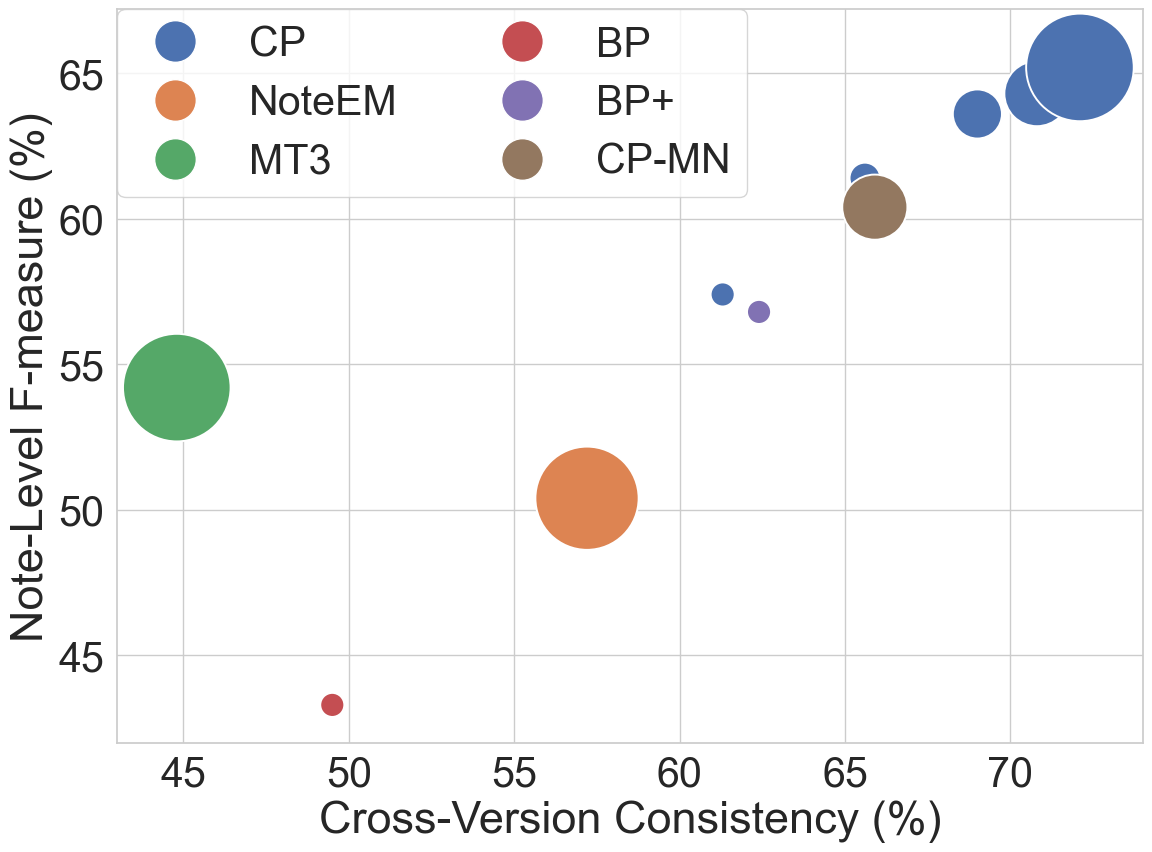

In [30]:
runs = ['MT3', 'BP', 'BP+_42', 'CP-XS_42', 'CP-S_42', 'CP-M_42', 'CP-L_42', 'CP-XL_42', 'NoteEM', 'CP-MusicNet_42']
subset = performance_df.loc[runs].reset_index()
subset['experiment'] = subset['experiment'].map(strip_seed)

MAP_SIZES = {
    'MT3': 60000, 'NoteEM': 55000, 'BP': 10, 'BP+': 10,
    'CP-XS': 10, 'CP-S': 2000, 'CP-M': 10000, 'CP-L': 20000, 'CP-XL': 60000, 'CP-MusicNet': 20000,
}
subset['size'] = subset['experiment'].map(MAP_SIZES)
subset['experiment'] = subset['experiment'].replace({'CP-MusicNet': 'CP-MN'})
subset['experiment'] = subset['experiment'].apply(lambda x: "CP" if x.startswith("CP-") and x != "CP-MN" else x)

model_order = ["CP", "NoteEM", "MT3", "BP", "BP+", "CP-MN"]
subset["experiment"] = pd.Categorical(subset["experiment"], categories=model_order, ordered=True)

sns.set_theme(style="whitegrid", font_scale=2.7)
fig, ax = plt.subplots(figsize=(12.3, 9.3))
sns.scatterplot(data=subset, y="rubato_AMT_100_F-measure_no_offset", x="rubato_cvc", hue="experiment",
                size="size", sizes=(300, 6000), legend=False, ax=ax)

palette = sns.color_palette()
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=palette[i], markersize=30, label=exp)
           for i, exp in enumerate(model_order)]
ax.legend(handles=handles, title="", ncol=2, borderaxespad=0)
ax.set_ylabel("Note-Level F-measure (%)")
ax.set_xlabel("Cross-Version Consistency (%)")
plt.xlim(43, 74)
plt.ylim(42, 67.2)
plt.tight_layout()
plt.savefig(FIG_DIR / 'consistency_vs_efficacy.pdf', dpi=600, bbox_inches='tight')
plt.show()

## Figure 2: Piano, Synthesized and Real-World Versions
Frame-level F-measure of the decoded notes on RUBATO, by version type.

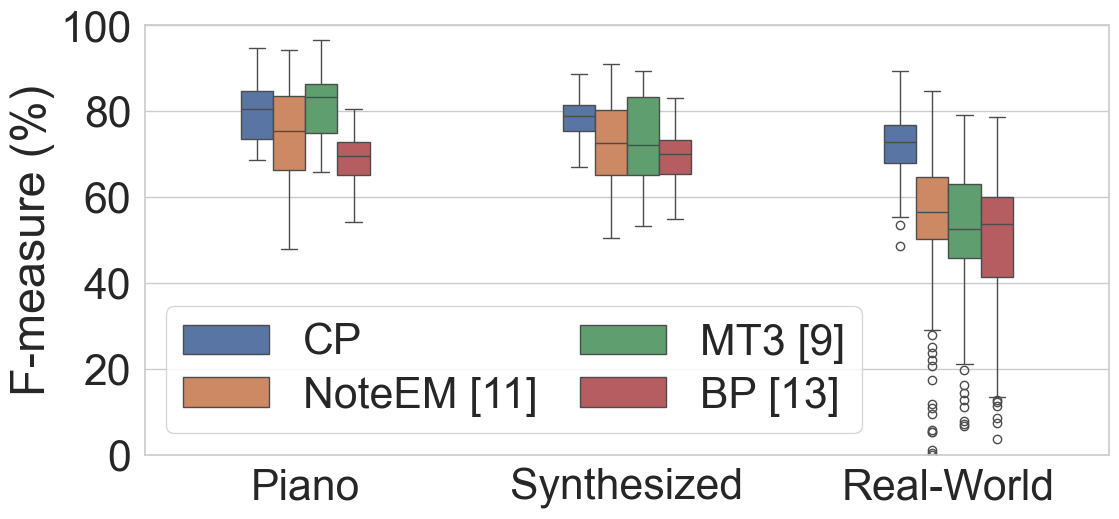

In [31]:
VERSION_TYPE_LABELS = {'SR': 'Piano', 'SY': 'Synthesized', 'OV': 'Real-World'}
FIGURE_LABELS = {'NoteEM': 'NoteEM [11]', 'MT3': 'MT3 [9]', 'BP': 'BP [13]', 'CP-L_42': 'CP'}
model_order = ["CP", "NoteEM [11]", "MT3 [9]", "BP [13]"]

sns.set_theme(style="whitegrid", font_scale=2.8)
palette = dict(zip(model_order, sns.color_palette()[:len(model_order)]))

metric = "AMT_FRAME_f_meas"
frames = []
for run in FIGURE_LABELS:
    df = load_track_results(RESULTS_DIR / "note_level" / f"{run}.csv.gz")
    df = df[df["dataset"] == "rubato"]
    df["version_type"] = df["id"].str.split("_").str[2]  # 
    df["version_type"] = df["version_type"].str.split("-").str[0]  # SR: piano renderings, SY: synthesized, OV: original versions
    df["model"] = FIGURE_LABELS[run]
    frames.append(df)
result = pd.concat(frames, ignore_index=True)
result[metric] = result[metric] * 100
result = result[result["version_type"].isin(VERSION_TYPE_LABELS)]
result["version_type"] = pd.Categorical(result["version_type"].map(VERSION_TYPE_LABELS),
                                        categories=VERSION_TYPE_LABELS.values(), ordered=True)
result["model"] = pd.Categorical(result["model"], categories=model_order, ordered=True)

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=result, x="version_type", y=metric, hue="model", width=0.4, ax=ax, palette=palette)
ax.legend(title='', ncol=2, columnspacing=1.0, labelspacing=0.3)
plt.xlabel("")
plt.ylabel("F-measure (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(FIG_DIR / f"rubato_version_comparison_{metric}_boxplot.pdf", dpi=600)
plt.show()